In [1]:
TEKSTBREEDTE = 108 / 25.4  # breedte van een afbeelding in het proefschrift (108 mm)
CORPS = 10           # lettergrootte van as-, legenda- en titeltekst (pt)
CORPS_KLEIN = 8.5    # lettergrootte van dichte labels en annotaties (pt)

# ── vaste kleuren per betekenis (gelijk in alle hoofdstukken) ─────────────
KLEUR_HOOFD = "#1A8259"                         # één reeks
KLEUR_VROEG, KLEUR_LAAT = "#A07FD8", "#1A8259"  # vroege / late periode
KLEUR_MIDDEN = "#E07B28"                        # tussenperiode (bij drie periodes)
KLEUR_DAG, KLEUR_NACHT = "#C98A3C", "#2A62A8"
KLEUR_MAN, KLEUR_VROUW = "#E100A3", "#3FB3CC"
KLEUR_WIJK = {1: "#2A62A8", 3: "#E07B28", 5: "#1BAF7A", 6: "#C2187F"}  # 5 = 5+11, 6 = 6+7



def komma_decimalen(fig):
    """Decimale komma in de standaard-asopmaak (ook kleurenschalen); eigen
    opmaak (FuncFormatter, vaste labels) blijft ongemoeid."""
    from matplotlib import ticker

    class Komma(ticker.Formatter):
        def __init__(self, basis):
            self.basis = basis
        def set_locs(self, locs):
            self.basis.set_locs(locs)
        def __call__(self, x, pos=None):
            return self.basis(x, pos).replace(".", ",")
        def get_offset(self):
            return self.basis.get_offset().replace(".", ",")

    for ax in fig.axes:
        for as_ in (ax.xaxis, ax.yaxis):
            for kies, zet in ((as_.get_major_formatter, as_.set_major_formatter),
                              (as_.get_minor_formatter, as_.set_minor_formatter)):
                f = kies()
                if isinstance(f, (ticker.ScalarFormatter, ticker.LogFormatter)):
                    f.axis = as_
                    zet(Komma(f))

def pas_breedte_aan(fig, doel=108 / 25.4, tight=None):
    """Maakt de figuur zo breed dat de opgeslagen afbeelding (ook met bbox 'tight')
    precies `doel` inch breed is. De letters blijven even groot; alleen het
    grafiekvlak wordt iets breder of smaller. Zet ook de decimalen op de assen
    om naar een komma."""
    import matplotlib as mpl
    komma_decimalen(fig)
    if tight is None:
        tight = mpl.rcParams["savefig.bbox"] == "tight"
    pad = mpl.rcParams["savefig.pad_inches"] if tight else 0
    oorspronkelijk = fig.get_figwidth()
    for _ in range(6):
        fig.canvas.draw()
        breedte = (fig.get_tightbbox().width if tight else fig.get_figwidth()) + 2 * pad
        if abs(breedte - doel) < 0.004:
            break
        nieuw = fig.get_figwidth() + (doel - breedte)
        if nieuw < 0.5 * doel:
            # een legende of label is op zich al breder dan het doel
            fig.set_figwidth(oorspronkelijk)
            print(f"Let op: figuur past niet binnen {doel * 25.4:.0f} mm; breedte niet aangepast.")
            break
        fig.set_figwidth(nieuw)

from pathlib import Path

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from scipy.stats import chi2_contingency
from matplotlib import font_manager
import bambi as bmb

FIG_DIR = Path("../../fig/H7")
TAB_DIR = Path("../../tab/H7")
FIG_DIR.mkdir(exist_ok=True)
TAB_DIR.mkdir(exist_ok=True)

SEED = 42
JAAR_MIN, JAAR_MAX = 1877, 1939
NACHTCATS = ["nacht", "avondschemering", "ochtendschemering"]
DAGCATS = ["dag"]
GESLACHTEN = ["man", "woman"]

# code in P_AGE_categories → label in figuur en tabel, van jong naar oud
KLASSEN = {
    "jong kind": "jong kind (0–4)",
    "kind": "kind (5–14)",
    "jongvolwassene": "jongvolwassene (15–24)",
    "volwassene": "volwassene (25–64)",
    "oudere": "oudere (65+)",
}

LETTERTYPE = "Libertinus Serif"
KLEUR_RATIO, KLEUR_RATIO_LIJN = "#B5495B", "#7a2f3d"
STEENGRIJS = "#96999B"

plt.rcParams.update({
    "font.family": "Libertinus Serif",
    "font.size": CORPS,
    "axes.labelsize": CORPS,
    "legend.fontsize": CORPS,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


def nl_getal(v, decimalen=0):
    """Getal met punt als duizendtal- en komma als decimaalteken."""
    tekst = f"{v:,.{decimalen}f}"
    return tekst.replace(",", "X").replace(".", ",").replace("X", ".")


def opslaan(fig, naam):
    for extensie in ("png",):
        pas_breedte_aan(fig, tight=True)
        fig.savefig(FIG_DIR / f"{naam}.{extensie}", dpi=300, bbox_inches="tight")

# ── eenvormige rasterlijnen in alle figuren ───────────────────────────────
import matplotlib as mpl
mpl.rcParams.update({
    "axes.grid": False,          # raster alleen waar het expliciet aangezet wordt
    "axes.axisbelow": True,      # raster achter de data
    "grid.color": "#96999B",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,
    "grid.linestyle": "-",
})


In [2]:
DATA_DIR = Path("../../data/algemeen/gebeurtenisdata_macro")

df = pd.concat(
    [pd.read_excel(bestand) for bestand in sorted(DATA_DIR.glob("*.xlsx"))
     if not bestand.name.startswith(("~$", "._"))],
    ignore_index=True,
)
df = df.dropna(subset=["year"])

print(f"{len(df)} rijen")

383125 rijen


In [3]:
basis = df.assign(
    gender_inferred=df["gender_inferred"].str.lower().str.strip(),
    leeftijdsgroep=df["P_AGE_categories"].str.lower().str.strip(),
    astronomical_category=df["astro"].str.lower().str.strip(),
)
basis = basis[
    basis["gender_inferred"].isin(GESLACHTEN)
    & basis["year"].between(JAAR_MIN, JAAR_MAX)
    & basis["astro"].isin(NACHTCATS + DAGCATS)
    & basis["leeftijdsgroep"].isin(KLASSEN)
].copy()

basis["year"] = basis["year"].astype(int)
basis["dag_nacht"] = np.where(basis["astro"].isin(NACHTCATS), "nacht", "dag")
basis["nacht"] = (basis["dag_nacht"] == "nacht").astype(int)

print(f"N = {nl_getal(len(basis))}")
print(basis.groupby(["leeftijdsgroep", "dag_nacht"]).size().unstack().reindex(list(KLASSEN)))

N = 49.973
dag_nacht         dag  nacht
leeftijdsgroep              
jong kind         162     83
kind             1589    637
jongvolwassene   6648   4178
volwassene      21403  13774
oudere           1008    491


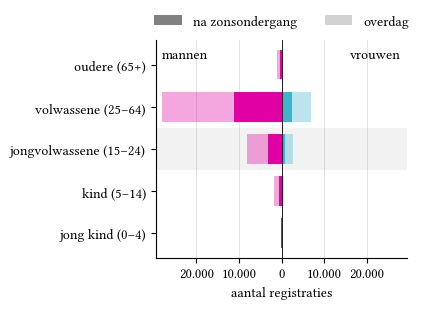

In [4]:
tel_pir = (
    basis.groupby(["leeftijdsgroep", "gender_inferred", "dag_nacht"])
    .size()
    .unstack(["gender_inferred", "dag_nacht"], fill_value=0)
    .reindex(list(KLASSEN), fill_value=0)
)

fig_pir, ax_pir = plt.subplots(figsize=(TEKSTBREEDTE, 3.2))
y = np.arange(len(KLASSEN))
rij_jong = list(KLASSEN).index("jongvolwassene")

ax_pir.axhspan(rij_jong - 0.5, rij_jong + 0.5, color=STEENGRIJS, alpha=0.12, lw=0, zorder=0)

for geslacht, kleur, teken in [("man", KLEUR_MAN, -1), ("woman", KLEUR_VROUW, 1)]:
    nacht = tel_pir[(geslacht, "nacht")].to_numpy()
    dag = tel_pir[(geslacht, "dag")].to_numpy()
    ax_pir.barh(y, teken * nacht, height=0.7, color=kleur, zorder=2)
    ax_pir.barh(y, teken * dag, left=teken * nacht, height=0.7,
                color=kleur, alpha=0.35, zorder=2)

grens = max(tel_pir["man"].sum(axis=1).max(), tel_pir["woman"].sum(axis=1).max()) * 1.05
ax_pir.set_xlim(-grens, grens)
ax_pir.axvline(0, color="black", lw=0.6, zorder=3)
ax_pir.xaxis.set_major_formatter(FuncFormatter(lambda v, _: nl_getal(abs(v))))
ax_pir.set_yticks(y, list(KLASSEN.values()))
ax_pir.xaxis.grid(True)
ax_pir.set_xlabel("aantal registraties")
ax_pir.text(-grens * 0.95, len(y) - 0.6, "mannen", ha="left", va="top")
ax_pir.text(grens * 0.95, len(y) - 0.6, "vrouwen", ha="right", va="top")
ax_pir.legend(
    [Patch(facecolor="grey"), Patch(facecolor="grey", alpha=0.35)],
    ["na zonsondergang", "overdag"],
    frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2,  # boven de grafiek
)

fig_pir.tight_layout()
opslaan(fig_pir, "7.1_piramide_gender_leeftijd_dagnacht")
plt.show()

In [5]:
def rij_tabel1(deel):
    kruis = (
        pd.crosstab(deel["dag_nacht"], deel["gender_inferred"])
        .reindex(index=["dag", "nacht"], columns=GESLACHTEN, fill_value=0)
    )
    chi2_stat, p_waarde, _, _ = chi2_contingency(kruis)
    pct = (kruis["woman"] / kruis.sum(axis=1) * 100).round(1)
    return {
        "dag (n)": kruis.loc["dag"].sum(),
        "nacht (n)": kruis.loc["nacht"].sum(),
        "vrouwen dag (%)": pct["dag"],
        "vrouwen nacht (%)": pct["nacht"],
        "verschil (pp)": round(pct["nacht"] - pct["dag"], 1),  # op afgeronde waarden
        "p": p_waarde,
        "V": np.sqrt(chi2_stat / kruis.to_numpy().sum()),
    }


rijen_t1 = {label: rij_tabel1(basis[basis["leeftijdsgroep"] == code])
            for code, label in reversed(KLASSEN.items())}
rijen_t1["totaal"] = rij_tabel1(basis)

tabel1 = pd.DataFrame.from_dict(rijen_t1, orient="index")
tabel1.index.name = "leeftijdsgroep"

print(tabel1.to_string(formatters={
    "dag (n)": nl_getal,
    "nacht (n)": nl_getal,
    "vrouwen dag (%)": lambda v: nl_getal(v, 1),
    "vrouwen nacht (%)": lambda v: nl_getal(v, 1),
    "verschil (pp)": lambda v: ("+" if v > 0 else "") + nl_getal(v, 1),
    "p": lambda v: "<0,001" if v < 0.001 else nl_getal(v, 3),
    "V": lambda v: nl_getal(v, 3),
}))
tabel1.to_csv(TAB_DIR / "7.1_gender_leeftijd_dag_nacht.csv")

# Voor de tekst: welk deel van de registraties van mannen en vrouwen viel na zonsondergang?
nachtaandeel = (
    basis.groupby(["leeftijdsgroep", "gender_inferred"])["nacht"].mean()
    .unstack().reindex(list(KLASSEN))
)
nachtaandeel["verhouding v/m"] = nachtaandeel["woman"] / nachtaandeel["man"]
print("\n", nachtaandeel.round(3).to_string())

                       dag (n) nacht (n) vrouwen dag (%) vrouwen nacht (%) verschil (pp)      p     V
leeftijdsgroep                                                                                       
oudere (65+)             1.008       491            28,6              26,1          -2,5  0,340 0,025
volwassene (25–64)      21.403    13.774            20,9              18,5          -2,4 <0,001 0,030
jongvolwassene (15–24)   6.648     4.178            25,4              21,6          -3,8 <0,001 0,043
kind (5–14)              1.589       637            24,9              22,3          -2,6  0,210 0,027
jong kind (0–4)            162        83            36,4              27,7          -8,7  0,221 0,078
totaal                  30.810    19.163            22,4              19,5          -2,9 <0,001 0,035

 gender_inferred    man  woman  verhouding v/m
leeftijdsgroep                               
jong kind        0.368  0.280           0.762
kind             0.293  0.264           0.90

In [6]:
jong = basis[basis["leeftijdsgroep"] == "jongvolwassene"]

tel_tijd = (
    jong.groupby(["gender_inferred", "year"])["nacht"]
    .agg(n_nacht="sum", n_tot="size")
    .reset_index()
)

JAREN = np.arange(JAAR_MIN, JAAR_MAX + 1)
ONTBREEKT = sorted(set(JAREN) - set(tel_tijd["year"]))
X_tijd = ((JAREN - JAREN.mean()) / 10)[:, None]  # gecentreerd, in decennia

geslacht_idx = pd.Categorical(tel_tijd["gender_inferred"], categories=GESLACHTEN).codes
jaar_idx = tel_tijd["year"].to_numpy() - JAAR_MIN

print(f"N jongvolwassenen = {nl_getal(tel_tijd['n_tot'].sum())}")
print(f"jaren zonder data: {ONTBREEKT}")

N jongvolwassenen = 10.826
jaren zonder data: [1897, 1898, 1906, 1915, 1916, 1917, 1918]


In [7]:
M_TIJD = 20

with pm.Model(coords={"geslacht": GESLACHTEN, "jaar": JAREN}) as model_tijd:
    niveau = pm.Normal("niveau", -0.5, 1, dims="geslacht")

    # Eigen curve per geslacht, gedeelde gladheid
    ell = pm.InverseGamma("ell", alpha=5, beta=6)  # lengteschaal in decennia, ongeveer 1–2
    eta = pm.Gamma("eta", alpha=2, beta=4)         # amplitude op logitschaal, ongeveer 0,5
    gp = pm.gp.HSGP(m=[M_TIJD], c=1.5, drop_first=True,
                    cov_func=eta**2 * pm.gp.cov.Matern52(1, ls=ell))
    phi, sqrt_psd = gp.prior_linearized(X=X_tijd)
    coef = pm.Normal("coef", 0, 1, shape=(len(GESLACHTEN), M_TIJD - 1))
    f = pt.dot(coef * sqrt_psd, phi.T)  # (geslacht, jaar)

    p = pm.Deterministic("p", pm.math.invlogit(niveau[:, None] + f),
                         dims=("geslacht", "jaar"))

    p_obs = p[geslacht_idx, jaar_idx]
    kappa = pm.Gamma("kappa", alpha=2, beta=0.02)
    pm.BetaBinomial(
        "nacht", alpha=p_obs * kappa, beta=(1 - p_obs) * kappa,
        n=tel_tijd["n_tot"].to_numpy(), observed=tel_tijd["n_nacht"].to_numpy(),
    )

    idata_tijd = pm.sample(tune=2000, target_accept=0.95, random_seed=SEED)

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [niveau, ell, eta, coef, kappa]


Output()

Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 15 seconds.


In [8]:
print(az.summary(idata_tijd, var_names=["niveau", "ell", "eta", "kappa"]).round(3))
print(f"divergenties: {int(idata_tijd.sample_stats['diverging'].sum())}")
print(f"max r_hat curves: {float(az.rhat(idata_tijd, var_names=['p'])['p'].max()):.3f}")

                 mean      sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  \
niveau[man]    -0.294   0.051  -0.387   -0.197      0.001    0.001    4262.0   
niveau[woman]  -0.573   0.066  -0.704   -0.457      0.001    0.001    4423.0   
ell             1.224   0.407   0.546    1.948      0.009    0.006    2210.0   
eta             0.412   0.149   0.189    0.694      0.004    0.002    1660.0   
kappa          56.465  14.960  31.912   84.752      0.264    0.191    3319.0   

               ess_tail  r_hat  
niveau[man]      3125.0    1.0  
niveau[woman]    2981.0    1.0  
ell              2873.0    1.0  
eta              2540.0    1.0  
kappa            3109.0    1.0  
divergenties: 0
max r_hat curves: 1.002


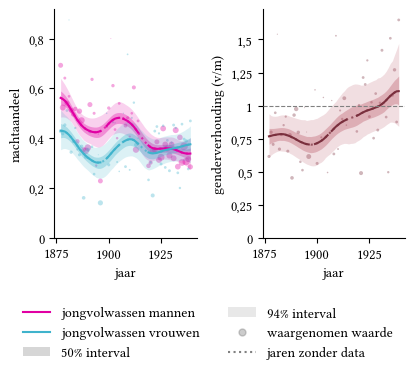

In [9]:
p_tijd = (idata_tijd.posterior["p"].stack(trekking=("chain", "draw"))
          .transpose("geslacht", "jaar", "trekking").values)
ratio_tijd = p_tijd[1] / p_tijd[0]


def banden(ax, trekkingen, kleur):
    for prob, alfa in [(0.94, 0.18), (0.50, 0.32)]:
        lo, hi = np.quantile(trekkingen, [(1 - prob) / 2, (1 + prob) / 2], axis=1)
        ax.fill_between(JAREN, lo, hi, color=kleur, alpha=alfa, lw=0, zorder=2)


def lijn_met_gaten(ax, waarden, kleur):
    """Volle lijn waar data is, stippellijn over ontbrekende jaren."""
    ax.plot(JAREN, waarden, color=kleur, lw=1.5, linestyle=":", alpha=0.7, zorder=3)
    ax.plot(JAREN, np.where(np.isin(JAREN, ONTBREEKT), np.nan, waarden),
            color=kleur, lw=1.5, zorder=4)


ruw = tel_tijd.assign(aandeel=lambda d: d["n_nacht"] / d["n_tot"])
n_max = ruw["n_tot"].max()

fig_tijd, (ax_a, ax_r) = plt.subplots(1, 2, figsize=(TEKSTBREEDTE, 3.0))

for i, (geslacht, kleur) in enumerate([("man", KLEUR_MAN), ("woman", KLEUR_VROUW)]):
    banden(ax_a, p_tijd[i], kleur)
    lijn_met_gaten(ax_a, np.median(p_tijd[i], axis=1), kleur)
    sub = ruw[ruw["gender_inferred"] == geslacht]
    ax_a.scatter(sub["year"], sub["aandeel"], s=sub["n_tot"] / n_max * 30,
                 color=kleur, alpha=0.35, lw=0, zorder=1)

piv = ruw.pivot(index="year", columns="gender_inferred", values=["aandeel", "n_tot"]).dropna()
ratio_ruw = (piv[("aandeel", "woman")] / piv[("aandeel", "man")]).replace(np.inf, np.nan)

banden(ax_r, ratio_tijd, KLEUR_RATIO)
lijn_met_gaten(ax_r, np.median(ratio_tijd, axis=1), KLEUR_RATIO_LIJN)
ax_r.scatter(ratio_ruw.index, ratio_ruw, s=piv["n_tot"].min(axis=1) / n_max * 30,
             color=KLEUR_RATIO_LIJN, alpha=0.35, lw=0, zorder=1)
ax_r.axhline(1, color="grey", lw=0.8, linestyle="--", zorder=5)

ax_a.set_ylabel("nachtaandeel")
ax_r.set_ylabel("genderverhouding (v/m)")
for ax in (ax_a, ax_r):
    ax.set_xlabel("jaar")
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}".replace(".", ",")))

fig_tijd.tight_layout()
fig_tijd.legend(
    [Line2D([], [], color=KLEUR_MAN, lw=1.5),
     Line2D([], [], color=KLEUR_VROUW, lw=1.5),
     Patch(facecolor="grey", alpha=0.32, lw=0),
     Patch(facecolor="grey", alpha=0.18, lw=0),
     Line2D([], [], marker="o", linestyle="none", color="grey", alpha=0.4, markersize=5),
     Line2D([], [], linestyle=":", color="grey", lw=1.5)],
    ["jongvolwassen mannen", "jongvolwassen vrouwen", "50% interval",
     "94% interval", "waargenomen waarde", "jaren zonder data"],
    frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, 0.0),
)
#opslaan(fig_tijd, "bayes_nachtaandeel_jongvolwassenen")
plt.show()

In [10]:
NIGHT_CATEGORIES = ["nacht", "avondschemering", "ochtendschemering"]
DAY_CATEGORIES = ["dag"]

WIJK_SAMENVOEGEN = {7: 6, 11: 5}

SEED = 42

YEAR_MIN = 1877
YEAR_MAX = 1939

AGE_MIN = 15
AGE_MAX = 24

In [11]:
df["P_AGE_clean"] = pd.to_numeric(df["P_AGE_clean"], errors="coerce")

model_data = df[
    df["gender_inferred"].isin(["man", "woman"])
    & df["year"].between(YEAR_MIN, YEAR_MAX)
    & df["P_AGE_clean"].between(AGE_MIN, AGE_MAX)
    & df["astro"].isin(NIGHT_CATEGORIES + DAY_CATEGORIES)
].copy()

model_data["nacht"] = model_data["astro"].isin(NIGHT_CATEGORIES).astype(int)

YEAR_MEAN = (
    model_data.groupby(["year", "gender_inferred"]).size()
    .reset_index()["year"].mean()
)

print(f"{len(model_data):,} registraties | YEAR_MEAN = {YEAR_MEAN:.2f}")

10,826 registraties | YEAR_MEAN = 1907.80


In [12]:
wijk_data = (
    model_data
    .assign(wijk=model_data["district"].replace(WIJK_SAMENVOEGEN))
    .dropna(subset=["wijk"])
    .groupby(["year", "wijk", "gender_inferred"])["nacht"]
    .agg(n_nacht="sum", n_tot="size")
    .reset_index()
)

wijk_data["wijk"] = wijk_data["wijk"].astype(int).astype(str)
wijk_data["jaar_c"] = wijk_data["year"] - YEAR_MEAN

wijk_data.to_csv(TAB_DIR / "nachtregistraties_per_wijk_jaar_gender.csv", index=False)

print(f"{len(wijk_data)} cellen | {wijk_data['n_tot'].sum():,} registraties")
print(f"Zonder wijk: {len(model_data) - wijk_data['n_tot'].sum():,}")
print(wijk_data.groupby("wijk")["n_tot"].sum())

194 cellen | 10,826 registraties
Zonder wijk: 0
wijk
1     997
3    5367
5    1244
6    2793
8     185
9     240
Name: n_tot, dtype: int64


In [13]:
per_wijk = wijk_data.groupby(["wijk", "gender_inferred"])[["n_nacht", "n_tot"]].sum()
per_wijk["aandeel"] = per_wijk["n_nacht"] / per_wijk["n_tot"]

overzicht = per_wijk["aandeel"].unstack()
overzicht["verhouding"] = overzicht["woman"] / overzicht["man"]
print(overzicht.round(2))

gender_inferred   man  woman  verhouding
wijk                                    
1                0.48   0.28        0.59
3                0.40   0.35        0.88
5                0.41   0.41        0.99
6                0.36   0.38        1.05
8                0.35   0.18        0.51
9                0.43   0.35        0.81


In [14]:
TERM_HSGP = "hsgp(jaar_c, m=20, c=1.5, by=gender_inferred)"

PRIOR_HSGP = {
    "sigma": bmb.Prior("Exponential", lam=1),
    "ell": bmb.Prior("InverseGamma", alpha=4, beta=40),
}
PRIOR_WIJK = bmb.Prior("Normal", mu=0, sigma=bmb.Prior("HalfNormal", sigma=0.5))

YEARS = np.arange(YEAR_MIN, YEAR_MAX + 1)
FIT_KWARGS = dict(draws=2000, tune=2000, chains=4, cores=1,
                  target_accept=0.95, random_seed=SEED)

In [15]:
jaar_data = (
    wijk_data.groupby(["year", "gender_inferred"])[["n_nacht", "n_tot"]]
    .sum()
    .reset_index()
)
jaar_data["jaar_c"] = jaar_data["year"] - YEAR_MEAN

model_basis = bmb.Model(
    f"p(n_nacht, n_tot) ~ 0 + gender_inferred + {TERM_HSGP}",
    data=jaar_data,
    family="beta_binomial",
    priors={TERM_HSGP: PRIOR_HSGP},
)
idata_basis = model_basis.fit(**FIT_KWARGS)

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [kappa, gender_inferred, hsgp(jaar_c, m=20, c=1.5, by=gender_inferred)_sigma, hsgp(jaar_c, m=20, c=1.5, by=gender_inferred)_ell, hsgp(jaar_c, m=20, c=1.5, by=gender_inferred)_weights_raw]


Output()

Output()

Output()

Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 90 seconds.


There were 2 divergences after tuning. Increase `target_accept` or reparameterize.


In [16]:
model_wijk = bmb.Model(
    f"p(n_nacht, n_tot) ~ 0 + gender_inferred + {TERM_HSGP} + (1 + gender_inferred | wijk)",
    data=wijk_data,
    family="beta_binomial",
    priors={
        TERM_HSGP: PRIOR_HSGP,
        "1|wijk": PRIOR_WIJK,
        "gender_inferred|wijk": PRIOR_WIJK,
    },
)
idata_wijk = model_wijk.fit(**FIT_KWARGS)

for naam, idata in [("basis", idata_basis), ("wijk", idata_wijk)]:
    diag = az.summary(idata, hdi_prob=0.94)[["r_hat", "ess_bulk"]]
    print(f"{naam}: max r_hat {diag['r_hat'].max():.3f} | min ESS {diag['ess_bulk'].min():.0f}")

print(az.summary(idata_wijk, var_names=["gender_inferred|wijk"], hdi_prob=0.94))

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [kappa, gender_inferred, hsgp(jaar_c, m=20, c=1.5, by=gender_inferred)_sigma, hsgp(jaar_c, m=20, c=1.5, by=gender_inferred)_ell, hsgp(jaar_c, m=20, c=1.5, by=gender_inferred)_weights_raw, 1|wijk_sigma, 1|wijk_offset, gender_inferred|wijk_sigma, gender_inferred|wijk_offset]


Output()

Output()

Output()

Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 247 seconds.


There were 6 divergences after tuning. Increase `target_accept` or reparameterize.


basis: max r_hat 1.000 | min ESS 1746


wijk: max r_hat 1.000 | min ESS 2051
                                 mean     sd  hdi_3%  hdi_97%  mcse_mean  \
gender_inferred|wijk[woman, 1] -0.097  0.172  -0.468    0.178      0.002   
gender_inferred|wijk[woman, 3]  0.025  0.138  -0.231    0.320      0.002   
gender_inferred|wijk[woman, 5]  0.124  0.188  -0.160    0.530      0.003   
gender_inferred|wijk[woman, 6]  0.082  0.155  -0.162    0.430      0.002   
gender_inferred|wijk[woman, 8] -0.118  0.237  -0.652    0.218      0.003   
gender_inferred|wijk[woman, 9] -0.025  0.176  -0.384    0.313      0.002   

                                mcse_sd  ess_bulk  ess_tail  r_hat  
gender_inferred|wijk[woman, 1]    0.002    7838.0    6758.0    1.0  
gender_inferred|wijk[woman, 3]    0.001    8629.0    6229.0    1.0  
gender_inferred|wijk[woman, 5]    0.002    5666.0    6128.0    1.0  
gender_inferred|wijk[woman, 6]    0.001    7123.0    6750.0    1.0  
gender_inferred|wijk[woman, 8]    0.002    7764.0    7236.0    1.0  
gender_inferred|

In [17]:
grid_jaar = pd.DataFrame({
    "gender_inferred": np.repeat(["man", "woman"], len(YEARS)),
    "year": np.tile(YEARS, 2),
})
grid_jaar["jaar_c"] = grid_jaar["year"] - YEAR_MEAN

def voorspel(model, idata):
    pred = model.predict(idata, data=grid_jaar, kind="response_params",
                         include_group_specific=False, inplace=False)
    naam = "mu" if "mu" in pred.posterior else "p"
    return pred.posterior[naam].stack(sample=("chain", "draw")).values.reshape(2, len(YEARS), -1)


p_basis = voorspel(model_basis, idata_basis)
p_wijk = voorspel(model_wijk, idata_wijk)

print(p_basis.shape, p_wijk.shape)

(2, 63, 8000) (2, 63, 8000)


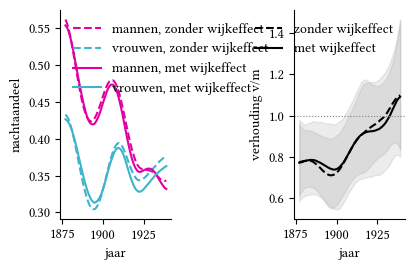

In [18]:
KLEUREN = {"man": KLEUR_MAN, "woman": KLEUR_VROUW}
LABELS = {"man": "mannen", "woman": "vrouwen"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(TEKSTBREEDTE, 2.8), sharex=True)

for naam, p, stijl in [("zonder wijkeffect", p_basis, "--"), ("met wijkeffect", p_wijk, "-")]:
    for i, g in enumerate(["man", "woman"]):
        ax1.plot(YEARS, np.median(p[i], axis=1), stijl, color=KLEUREN[g],
                 label=f"{LABELS[g]}, {naam}")

    ratio = p[1] / p[0]
    lo, hi = np.percentile(ratio, [3, 97], axis=1)
    ax2.fill_between(YEARS, lo, hi, color="grey", alpha=0.15)
    ax2.plot(YEARS, np.median(ratio, axis=1), stijl, color="black", label=naam)

ax2.axhline(1, color="grey", lw=0.8, ls=":")
ax1.set(xlabel="jaar", ylabel="nachtaandeel")
ax2.set(xlabel="jaar", ylabel="verhouding v/m")
ax1.legend(frameon=False, fontsize=CORPS)
ax2.legend(frameon=False, fontsize=CORPS)
fig.tight_layout()
#fig.savefig(FIG_DIR / "robuustheid_wijkeffect.png", dpi=300)

In [19]:
overzicht = wijk_data.groupby("wijk").agg(
    van=("year", "min"),
    tot=("year", "max"),
    jaren=("year", "nunique"),
    registraties=("n_tot", "sum"),
)
print(overzicht)

       van   tot  jaren  registraties
wijk                                 
1     1879  1901      9           997
3     1877  1939     38          5367
5     1878  1937     15          1244
6     1895  1939     29          2793
8     1890  1890      1           185
9     1910  1920      5           240


In [20]:
WIJKEN = ["1", "3", "5", "6"]

apart_data = wijk_data[wijk_data["wijk"].isin(WIJKEN)].copy()
apart_data["wijk_gender"] = apart_data["wijk"] + "_" + apart_data["gender_inferred"]

TERM_HSGP_WG = "hsgp(jaar_c, m=15, c=1.5, by=wijk_gender)"

model_apart = bmb.Model(
    f"p(n_nacht, n_tot) ~ 0 + wijk_gender + {TERM_HSGP_WG}",
    data=apart_data,
    family="beta_binomial",
    priors={TERM_HSGP_WG: PRIOR_HSGP},
)
idata_apart = model_apart.fit(**FIT_KWARGS)

diag = az.summary(idata_apart, hdi_prob=0.94)[["r_hat", "ess_bulk"]]
print(f"max r_hat {diag['r_hat'].max():.3f} | min ESS {diag['ess_bulk'].min():.0f}")

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [kappa, wijk_gender, hsgp(jaar_c, m=15, c=1.5, by=wijk_gender)_sigma, hsgp(jaar_c, m=15, c=1.5, by=wijk_gender)_ell, hsgp(jaar_c, m=15, c=1.5, by=wijk_gender)_weights_raw]


Output()

Output()

Output()

Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 169 seconds.


There were 15 divergences after tuning. Increase `target_accept` or reparameterize.


max r_hat 1.000 | min ESS 1324


In [21]:
bereik = apart_data.groupby("wijk")["year"].agg(["min", "max"])

grid = pd.DataFrame(
    [(w, g, j) for w in WIJKEN for g in ["man", "woman"]
     for j in range(bereik.loc[w, "min"], bereik.loc[w, "max"] + 1)],
    columns=["wijk", "gender_inferred", "year"],
)
grid["wijk_gender"] = grid["wijk"] + "_" + grid["gender_inferred"]
grid["jaar_c"] = grid["year"] - YEAR_MEAN

met_data = set(zip(apart_data["wijk"], apart_data["year"]))
grid["data"] = [(w, j) in met_data for w, j in zip(grid["wijk"], grid["year"])]

pred = model_apart.predict(idata_apart, data=grid, kind="response_params", inplace=False)
mu = pred.posterior["mu"].stack(sample=("chain", "draw")).values

is_man = grid["gender_inferred"].eq("man").to_numpy()


def samenvatten(waarden, rijen):
    tabel = rijen.reset_index(drop=True).copy()
    tabel["mediaan"] = np.median(waarden, axis=1)
    tabel["lo"], tabel["hi"] = np.percentile(waarden, [3, 97], axis=1)
    return tabel


aandeel = samenvatten(mu, grid)
verhouding = samenvatten(mu[~is_man] / mu[is_man], grid[is_man])

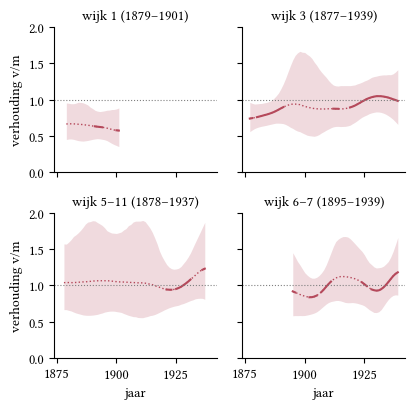

In [22]:
TITELS = {"1": "wijk 1", "3": "wijk 3", "5": "wijk 5–11", "6": "wijk 6–7"}


def lijn_met_gaten(ax, sel, kleur):
    """Doorgetrokken waar data zijn, gestippeld over ontbrekende jaren."""
    ax.plot(sel["year"], sel["mediaan"], ":", color=kleur, lw=1)
    ax.plot(sel["year"], sel["mediaan"].where(sel["data"]), "-", color=kleur)


fig, axes = plt.subplots(2, 2, figsize=(TEKSTBREEDTE, 4.2), sharex=True, sharey=True)

for ax, w in zip(axes.flat, WIJKEN):
    sel = verhouding[verhouding["wijk"] == w]
    ax.fill_between(sel["year"], sel["lo"], sel["hi"], color=KLEUR_RATIO, alpha=0.2, lw=0)
    lijn_met_gaten(ax, sel, KLEUR_RATIO)
    ax.axhline(1, ls=":", color="grey", lw=0.8)
    ax.set_title(f"{TITELS[w]} ({bereik.loc[w, 'min']}–{bereik.loc[w, 'max']})", fontsize=CORPS)
    ax.set_ylim(0, 2)

for ax in axes[:, 0]:
    ax.set_ylabel("verhouding v/m")
for ax in axes[1]:
    ax.set_xlabel("jaar")

fig.tight_layout()
#fig.savefig(FIG_DIR / "verhouding_per_wijk.png", dpi=300)

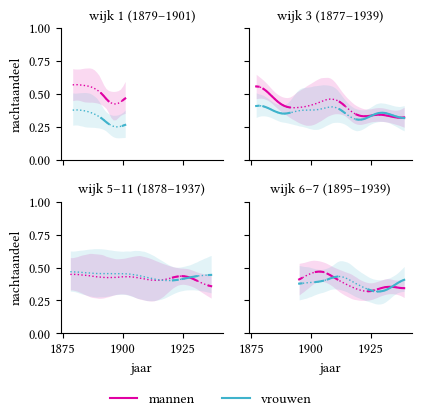

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(TEKSTBREEDTE, 4.2), sharex=True, sharey=True)

for ax, w in zip(axes.flat, WIJKEN):
    for g in ["man", "woman"]:
        sel = aandeel[(aandeel["wijk"] == w) & (aandeel["gender_inferred"] == g)]
        ax.fill_between(sel["year"], sel["lo"], sel["hi"], color=KLEUREN[g], alpha=0.15, lw=0)
        lijn_met_gaten(ax, sel, KLEUREN[g])
    ax.set_title(f"{TITELS[w]} ({bereik.loc[w, 'min']}–{bereik.loc[w, 'max']})", fontsize=CORPS)
    ax.set_ylim(0, 1)

for ax in axes[:, 0]:
    ax.set_ylabel("nachtaandeel")
for ax in axes[1]:
    ax.set_xlabel("jaar")

handles = [plt.Line2D([], [], color=KLEUREN[g], label=LABELS[g]) for g in ["man", "woman"]]
fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False)
fig.tight_layout(rect=[0, 0.06, 1, 1])
#fig.savefig(FIG_DIR / "nachtaandeel_per_wijk.png", dpi=300)

In [24]:
def samenvatten(waarden, rijen):
    tabel = rijen.reset_index(drop=True).copy()
    tabel["mediaan"] = np.median(waarden, axis=1)
    tabel["lo94"], tabel["lo50"], tabel["hi50"], tabel["hi94"] = np.percentile(
        waarden, [3, 25, 75, 97], axis=1
    )
    return tabel


aandeel = samenvatten(mu, grid)

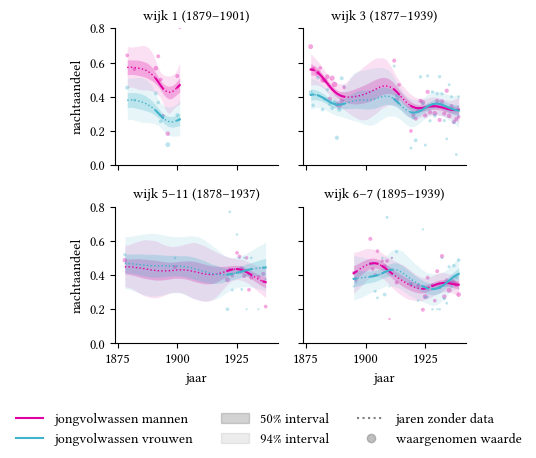

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(TEKSTBREEDTE, 4.6), sharex=True, sharey=True)

for ax, w in zip(axes.flat, WIJKEN):
    for g in ["man", "woman"]:
        sel = aandeel[(aandeel["wijk"] == w) & (aandeel["gender_inferred"] == g)]
        ax.fill_between(sel["year"], sel["lo94"], sel["hi94"], color=KLEUREN[g], alpha=0.12, lw=0)
        ax.fill_between(sel["year"], sel["lo50"], sel["hi50"], color=KLEUREN[g], alpha=0.25, lw=0)
        lijn_met_gaten(ax, sel, KLEUREN[g])

        obs = apart_data[(apart_data["wijk"] == w) & (apart_data["gender_inferred"] == g)]
        ax.scatter(obs["year"], obs["n_nacht"] / obs["n_tot"], s=np.sqrt(obs["n_tot"]),
                   color=KLEUREN[g], alpha=0.35, lw=0)

    ax.set_title(f"{TITELS[w]} ({bereik.loc[w, 'min']}–{bereik.loc[w, 'max']})", fontsize=CORPS)
    ax.set_ylim(0, 0.8)
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes[:, 0]:
    ax.set_ylabel("nachtaandeel")
for ax in axes[1]:
    ax.set_xlabel("jaar")

handles = [
    plt.Line2D([], [], color=KLEUREN["man"], label="jongvolwassen mannen"),
    plt.Line2D([], [], color=KLEUREN["woman"], label="jongvolwassen vrouwen"),
    plt.Rectangle((0, 0), 1, 1, color="grey", alpha=0.35, label="50% interval"),
    plt.Rectangle((0, 0), 1, 1, color="grey", alpha=0.15, label="94% interval"),
    plt.Line2D([], [], ls=":", color="grey", label="jaren zonder data"),
    plt.Line2D([], [], ls="", marker="o", color="grey", alpha=0.5, label="waargenomen waarde"),
]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=CORPS)
fig.tight_layout(rect=[0, 0.12, 1, 1])
#fig.savefig(FIG_DIR / "afbeelding2_nachtaandeel_per_wijk.png", dpi=300)

In [26]:
nacht_data = (
    model_data[model_data["nacht"] == 1]
    .assign(
        wijk=lambda d: d["district"].replace(WIJK_SAMENVOEGEN),
        vrouw=lambda d: d["gender_inferred"].eq("woman").astype(int),
    )
    .dropna(subset=["wijk"])
    .assign(wijk=lambda d: d["wijk"].astype(int).astype(str))
    .query("wijk in @WIJKEN")
    .groupby(["year", "wijk"])["vrouw"]
    .agg(n_vrouw="sum", n_tot="size")
    .reset_index()
)
nacht_data["jaar_c"] = nacht_data["year"] - YEAR_MEAN

print(f"{len(nacht_data)} cellen | {nacht_data['n_tot'].sum():,} nachtelijke registraties")
print(nacht_data.groupby("wijk")[["n_vrouw", "n_tot"]].sum().assign(
    aandeel=lambda t: (t["n_vrouw"] / t["n_tot"]).round(3)))

91 cellen | 4,028 nachtelijke registraties
      n_vrouw  n_tot  aandeel
wijk                         
1         126    388    0.325
3         446   2099    0.212
5          82    515    0.159
6         206   1026    0.201


In [27]:
TERM_HSGP_W = "hsgp(jaar_c, m=15, c=1.5, by=wijk)"

model_nacht = bmb.Model(
    f"p(n_vrouw, n_tot) ~ 0 + wijk + {TERM_HSGP_W}",
    data=nacht_data,
    family="beta_binomial",
    priors={TERM_HSGP_W: PRIOR_HSGP},
)
idata_nacht = model_nacht.fit(**FIT_KWARGS)

diag = az.summary(idata_nacht, hdi_prob=0.94)[["r_hat", "ess_bulk"]]
print(f"max r_hat {diag['r_hat'].max():.3f} | min ESS {diag['ess_bulk'].min():.0f}")

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [kappa, wijk, hsgp(jaar_c, m=15, c=1.5, by=wijk)_sigma, hsgp(jaar_c, m=15, c=1.5, by=wijk)_ell, hsgp(jaar_c, m=15, c=1.5, by=wijk)_weights_raw]


Output()

Output()

Output()

Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 92 seconds.


There were 85 divergences after tuning. Increase `target_accept` or reparameterize.


max r_hat 1.000 | min ESS 1501


In [28]:
bereik_nacht = nacht_data.groupby("wijk")["year"].agg(["min", "max"])

grid_nacht = pd.DataFrame(
    [(w, j) for w in WIJKEN
     for j in range(bereik_nacht.loc[w, "min"], bereik_nacht.loc[w, "max"] + 1)],
    columns=["wijk", "year"],
)
grid_nacht["jaar_c"] = grid_nacht["year"] - YEAR_MEAN

met_data = set(zip(nacht_data["wijk"], nacht_data["year"]))
grid_nacht["data"] = [(w, j) in met_data for w, j in zip(grid_nacht["wijk"], grid_nacht["year"])]

pred = model_nacht.predict(idata_nacht, data=grid_nacht, kind="response_params", inplace=False)
mu_nacht = pred.posterior["mu"].stack(sample=("chain", "draw")).values

aandeel_vrouwen = samenvatten(mu_nacht, grid_nacht)

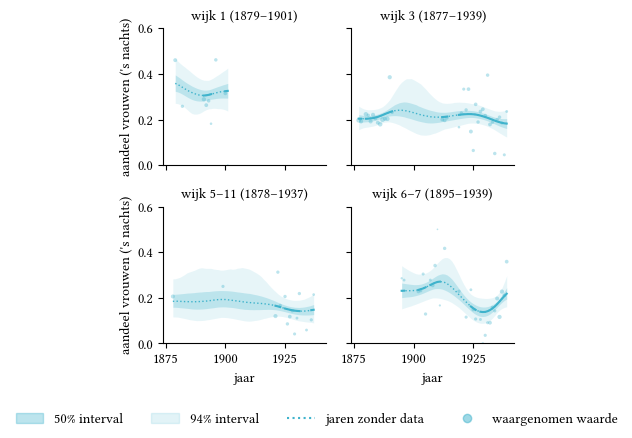

In [29]:
KLEUR_VROUW = KLEUREN["woman"]

fig, axes = plt.subplots(2, 2, figsize=(TEKSTBREEDTE, 4.4), sharex=True, sharey=True)

for ax, w in zip(axes.flat, WIJKEN):
    sel = aandeel_vrouwen[aandeel_vrouwen["wijk"] == w]
    ax.fill_between(sel["year"], sel["lo94"], sel["hi94"], color=KLEUR_VROUW, alpha=0.12, lw=0)
    ax.fill_between(sel["year"], sel["lo50"], sel["hi50"], color=KLEUR_VROUW, alpha=0.25, lw=0)
    lijn_met_gaten(ax, sel, KLEUR_VROUW)

    obs = nacht_data[nacht_data["wijk"] == w]
    ax.scatter(obs["year"], obs["n_vrouw"] / obs["n_tot"], s=np.sqrt(obs["n_tot"]),
               color=KLEUR_VROUW, alpha=0.35, lw=0)

    ax.set_title(f"{TITELS[w]} ({bereik_nacht.loc[w, 'min']}–{bereik_nacht.loc[w, 'max']})", fontsize=CORPS)
    ax.set_ylim(0, 0.6)
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes[:, 0]:
    ax.set_ylabel("aandeel vrouwen ('s nachts)")
for ax in axes[1]:
    ax.set_xlabel("jaar")

handles = [
    plt.Rectangle((0, 0), 1, 1, color=KLEUR_VROUW, alpha=0.35, label="50% interval"),
    plt.Rectangle((0, 0), 1, 1, color=KLEUR_VROUW, alpha=0.15, label="94% interval"),
    plt.Line2D([], [], ls=":", color=KLEUR_VROUW, label="jaren zonder data"),
    plt.Line2D([], [], ls="", marker="o", color=KLEUR_VROUW, alpha=0.5, label="waargenomen waarde"),
]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, fontsize=CORPS)
fig.tight_layout(rect=[0, 0.08, 1, 1])
#fig.savefig(FIG_DIR / "aandeel_vrouwen_nacht_per_wijk.png", dpi=300)

In [30]:
dagdeel_data = (
    model_data
    .assign(
        wijk=lambda d: d["district"].replace(WIJK_SAMENVOEGEN),
        vrouw=lambda d: d["gender_inferred"].eq("woman").astype(int),
        dagdeel=lambda d: np.where(d["nacht"] == 1, "nacht", "dag"),
    )
    .dropna(subset=["wijk"])
    .assign(wijk=lambda d: d["wijk"].astype(int).astype(str))
    .query("wijk in @WIJKEN")
    .groupby(["year", "wijk", "dagdeel"])["vrouw"]
    .agg(n_vrouw="sum", n_tot="size")
    .reset_index()
)
dagdeel_data["jaar_c"] = dagdeel_data["year"] - YEAR_MEAN
dagdeel_data["wijk_dagdeel"] = dagdeel_data["wijk"] + "_" + dagdeel_data["dagdeel"]

In [31]:
TERM_HSGP_WD = "hsgp(jaar_c, m=15, c=1.5, by=wijk_dagdeel)"

model_dagdeel = bmb.Model(
    f"p(n_vrouw, n_tot) ~ 0 + wijk_dagdeel + {TERM_HSGP_WD}",
    data=dagdeel_data,
    family="beta_binomial",
    priors={TERM_HSGP_WD: PRIOR_HSGP},
)
idata_dagdeel = model_dagdeel.fit(**FIT_KWARGS)

diag = az.summary(idata_dagdeel, hdi_prob=0.94)[["r_hat", "ess_bulk"]]
print(f"max r_hat {diag['r_hat'].max():.3f} | min ESS {diag['ess_bulk'].min():.0f}")

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [kappa, wijk_dagdeel, hsgp(jaar_c, m=15, c=1.5, by=wijk_dagdeel)_sigma, hsgp(jaar_c, m=15, c=1.5, by=wijk_dagdeel)_ell, hsgp(jaar_c, m=15, c=1.5, by=wijk_dagdeel)_weights_raw]


Output()

Output()

Output()

Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 159 seconds.


There were 34 divergences after tuning. Increase `target_accept` or reparameterize.


max r_hat 1.010 | min ESS 1552


In [32]:
bereik_dd = dagdeel_data.groupby("wijk")["year"].agg(["min", "max"])

grid_dd = pd.DataFrame(
    [(w, d, j) for w in WIJKEN for d in ["dag", "nacht"]
     for j in range(bereik_dd.loc[w, "min"], bereik_dd.loc[w, "max"] + 1)],
    columns=["wijk", "dagdeel", "year"],
)
grid_dd["wijk_dagdeel"] = grid_dd["wijk"] + "_" + grid_dd["dagdeel"]
grid_dd["jaar_c"] = grid_dd["year"] - YEAR_MEAN

met_data = set(zip(dagdeel_data["wijk"], dagdeel_data["year"]))
grid_dd["data"] = [(w, j) in met_data for w, j in zip(grid_dd["wijk"], grid_dd["year"])]

pred = model_dagdeel.predict(idata_dagdeel, data=grid_dd, kind="response_params", inplace=False)
aandeel_dd = samenvatten(pred.posterior["mu"].stack(sample=("chain", "draw")).values, grid_dd)

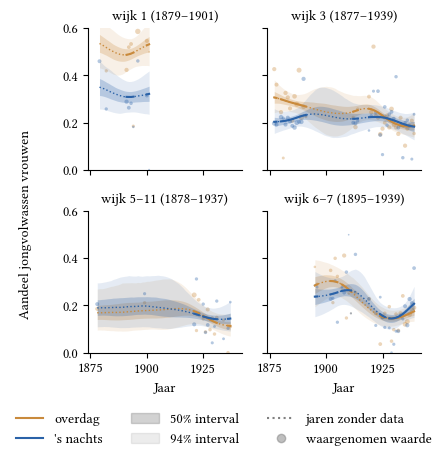

In [33]:
KLEUREN_DD = {"dag": KLEUR_DAG, "nacht": KLEUR_NACHT}

fig, axes = plt.subplots(2, 2, figsize=(TEKSTBREEDTE, 4.6), sharex=True, sharey=True)

for ax, w in zip(axes.flat, WIJKEN):
    for d in ["dag", "nacht"]:
        sel = aandeel_dd[(aandeel_dd["wijk"] == w) & (aandeel_dd["dagdeel"] == d)]
        ax.fill_between(sel["year"], sel["lo94"], sel["hi94"], color=KLEUREN_DD[d], alpha=0.12, lw=0)
        ax.fill_between(sel["year"], sel["lo50"], sel["hi50"], color=KLEUREN_DD[d], alpha=0.25, lw=0)
        lijn_met_gaten(ax, sel, KLEUREN_DD[d])

        obs = dagdeel_data[(dagdeel_data["wijk"] == w) & (dagdeel_data["dagdeel"] == d)]
        ax.scatter(obs["year"], obs["n_vrouw"] / obs["n_tot"], s=np.sqrt(obs["n_tot"]),
                   color=KLEUREN_DD[d], alpha=0.35, lw=0)

    ax.set_title(f"{TITELS[w]} ({bereik_dd.loc[w, 'min']}–{bereik_dd.loc[w, 'max']})", fontsize=CORPS)
    ax.set_ylim(0, 0.6)
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes[1]:
    ax.set_xlabel("Jaar")
fig.supylabel("Aandeel jongvolwassen vrouwen", fontsize=CORPS)

handles = [
    plt.Line2D([], [], color=KLEUREN_DD["dag"], label="overdag"),
    plt.Line2D([], [], color=KLEUREN_DD["nacht"], label="'s nachts"),
    plt.Rectangle((0, 0), 1, 1, color="grey", alpha=0.35, label="50% interval"),
    plt.Rectangle((0, 0), 1, 1, color="grey", alpha=0.15, label="94% interval"),
    plt.Line2D([], [], ls=":", color="grey", label="jaren zonder data"),
    plt.Line2D([], [], ls="", marker="o", color="grey", alpha=0.5, label="waargenomen waarde"),
]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=CORPS)
fig.tight_layout(rect=[0.02, 0.1, 1, 1])
#fig.savefig(FIG_DIR / "afbeelding2_aandeel_vrouwen_dag_nacht.pdf")
#fig.savefig(FIG_DIR / "aandeel_vrouwen_dag_nacht_alternatief.png", dpi=300)

In [34]:
print(df["E_TIME_grouped"].value_counts(dropna=False).sort_index())

E_TIME_grouped
0u-3u       21125
12u-15u     25944
15u-18u     34184
18u-21u     27481
21u-0u      21058
3u-6u        8131
6u-9u        9802
9u-12u      48667
NaN        186733
Name: count, dtype: int64


In [35]:
VENSTERS = {
    "dag": ["9u-12u", "12u-15u"],
    "nacht": ["21u-0u", "0u-3u"],
}

df["dagdeel"] = np.select(
    [df["E_TIME_grouped"].isin(VENSTERS["dag"]), df["E_TIME_grouped"].isin(VENSTERS["nacht"])],
    ["dag", "nacht"],
    default=None,
)

df["P_AGE_clean"] = pd.to_numeric(df["P_AGE_clean"], errors="coerce")

model_data = df[
    df["gender_inferred"].isin(["man", "woman"])
    & df["year"].between(YEAR_MIN, YEAR_MAX)
    & df["P_AGE_clean"].between(AGE_MIN, AGE_MAX)
    & df["dagdeel"].notna()
].copy()

model_data["nacht"] = model_data["dagdeel"].eq("nacht").astype(int)

print(f"{len(model_data):,} registraties")
print(pd.crosstab(model_data["dagdeel"], model_data["gender_inferred"], margins=True))

6,500 registraties
gender_inferred   man  woman   All
dagdeel                           
dag              3041   1052  4093
nacht            1874    533  2407
All              4915   1585  6500


In [36]:
controle = (
    model_data
    .assign(wijk=model_data["district"].replace(WIJK_SAMENVOEGEN))
    .dropna(subset=["wijk"])
    .assign(wijk=lambda d: d["wijk"].astype(int).astype(str))
    .groupby(["wijk", "dagdeel", "gender_inferred"])
    .size()
    .unstack(["dagdeel", "gender_inferred"], fill_value=0)
)
print(controle)

dagdeel           dag       nacht      
gender_inferred   man woman   man woman
wijk                                   
1                 179   237   169    90
3                1490   468   898   251
5                 383    69   271    51
6                 891   211   486   121
8                  48    32    22     8
9                  50    35    28    12


In [37]:
LEEFTIJD_GRENZEN = [0, 5, 15, 25, 65, np.inf]
LEEFTIJD_LABELS = ["Jong kind (0–4)", "Kind (5–14)", "Jongvolwassene (15–24)",
                   "Volwassene (25–64)", "Oudere (65+)"]

df["P_AGE_clean"] = pd.to_numeric(df["P_AGE_clean"], errors="coerce")
df["dagdeel"] = np.select(
    [df["E_TIME_grouped"].isin(VENSTERS["dag"]), df["E_TIME_grouped"].isin(VENSTERS["nacht"])],
    ["dag", "nacht"],
    default=None,
)

basis = df[
    df["gender_inferred"].isin(["man", "woman"])
    & df["year"].between(YEAR_MIN, YEAR_MAX)
    & df["P_AGE_clean"].notna()
    & df["dagdeel"].notna()
].copy()

basis["leeftijdsgroep"] = pd.cut(basis["P_AGE_clean"], LEEFTIJD_GRENZEN,
                                 labels=LEEFTIJD_LABELS, right=False)
basis["wijk"] = basis["district"].replace(WIJK_SAMENVOEGEN)

print(len(basis))

29430


In [38]:
def dag_nacht_tabel(data, groep):
    """Aandeel vrouwen overdag en 's nachts per groep, met chi-kwadraattoets."""
    rijen = []
    for naam, sub in data.groupby(groep, observed=True):
        t = (pd.crosstab(sub["gender_inferred"], sub["dagdeel"])
             .reindex(index=["woman", "man"], columns=["dag", "nacht"], fill_value=0))
        chi2, p, _, _ = chi2_contingency(t, correction=False)
        vrouwen = t.loc["woman"] / t.sum()
        rijen.append({
            groep: naam,
            "dag (n)": t["dag"].sum(),
            "nacht (n)": t["nacht"].sum(),
            "vrouwen dag (%)": round(100 * vrouwen["dag"], 1),
            "vrouwen nacht (%)": round(100 * vrouwen["nacht"], 1),
            "verschil (pp)": round(100 * (vrouwen["nacht"] - vrouwen["dag"]), 1),
            "p": round(p, 3),
            "V": round(np.sqrt(chi2 / t.values.sum()), 3),
        })
    return pd.DataFrame(rijen)

In [39]:
tabel1 = pd.concat([
    dag_nacht_tabel(basis, "leeftijdsgroep").iloc[::-1],
    dag_nacht_tabel(basis.assign(leeftijdsgroep="Totaal"), "leeftijdsgroep"),
], ignore_index=True)

print(tabel1.to_string(index=False))
#tabel1.to_csv("../../tab/H7/H3_tabel1_dag_nacht_leeftijd.csv", index=False)

        leeftijdsgroep  dag (n)  nacht (n)  vrouwen dag (%)  vrouwen nacht (%)  verschil (pp)     p     V
          Oudere (65+)      591        262             28.3               25.2           -3.1 0.354 0.032
    Volwassene (25–64)    13002       7805             20.9               19.4           -1.5 0.009 0.018
Jongvolwassene (15–24)     4093       2407             25.7               22.1           -3.6 0.001 0.040
           Kind (5–14)      877        273             25.3               26.7            1.4 0.637 0.014
       Jong kind (0–4)       82         38             39.0               23.7          -15.3 0.099 0.150
                Totaal    18645      10785             22.5               20.4           -2.1 0.000 0.025


In [40]:
model_data = basis[basis["leeftijdsgroep"] == "Jongvolwassene (15–24)"].copy()
model_data["nacht"] = model_data["dagdeel"].eq("nacht").astype(int)

wijk_basis = (
    model_data.dropna(subset=["wijk"])
    .assign(wijk=lambda d: d["wijk"].astype(int).astype(str))
)

tabel2 = pd.concat([
    dag_nacht_tabel(wijk_basis[wijk_basis["wijk"].isin(WIJKEN)], "wijk"),
    dag_nacht_tabel(wijk_basis.assign(wijk="Totaal"), "wijk"),
], ignore_index=True)
tabel2["wijk"] = tabel2["wijk"].map(TITELS).fillna(tabel2["wijk"])

print(tabel2.to_string(index=False))
#tabel2.to_csv("../../tab/H7/H3_tabel2_dag_nacht_wijk.csv", index=False)

     wijk  dag (n)  nacht (n)  vrouwen dag (%)  vrouwen nacht (%)  verschil (pp)     p     V
   wijk 1      416        259             57.0               34.7          -22.2 0.000 0.216
   wijk 3     1958       1149             23.9               21.8           -2.1 0.189 0.024
wijk 5–11      452        322             15.3               15.8            0.6 0.828 0.008
 wijk 6–7     1102        607             19.1               19.9            0.8 0.694 0.010
   Totaal     4093       2407             25.7               22.1           -3.6 0.001 0.040


In [41]:
dagdeel_data = (
    wijk_basis[wijk_basis["wijk"].isin(WIJKEN)]
    .assign(vrouw=lambda d: d["gender_inferred"].eq("woman").astype(int))
    .groupby(["year", "wijk", "dagdeel"])["vrouw"]
    .agg(n_vrouw="sum", n_tot="size")
    .reset_index()
)
dagdeel_data["jaar_c"] = dagdeel_data["year"] - YEAR_MEAN
dagdeel_data["wijk_dagdeel"] = dagdeel_data["wijk"] + "_" + dagdeel_data["dagdeel"]

bereik = dagdeel_data.groupby("wijk")["year"].agg(["min", "max"])

print(f"{len(dagdeel_data)} cellen | N = {dagdeel_data['n_tot'].sum():,}")
print(bereik)

182 cellen | N = 6,265
       min   max
wijk            
1     1879  1901
3     1877  1939
5     1878  1937
6     1895  1939


In [42]:
TERM_HSGP = "hsgp(jaar_c, m=15, c=1.5, by=wijk_dagdeel)"

model_dagdeel = bmb.Model(
    f"p(n_vrouw, n_tot) ~ 0 + wijk_dagdeel + {TERM_HSGP}",
    data=dagdeel_data,
    family="beta_binomial",
    priors={TERM_HSGP: {
        "sigma": bmb.Prior("Exponential", lam=1),
        "ell": bmb.Prior("InverseGamma", alpha=4, beta=40),
    }},
)

idata_dagdeel = model_dagdeel.fit(
    draws=2000, tune=2000, chains=4, cores=1,
    target_accept=0.95, random_seed=SEED,
)

diag = az.summary(idata_dagdeel, hdi_prob=0.94)[["r_hat", "ess_bulk"]]
print(f"max r_hat {diag['r_hat'].max():.3f} | min ESS {diag['ess_bulk'].min():.0f}")

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [kappa, wijk_dagdeel, hsgp(jaar_c, m=15, c=1.5, by=wijk_dagdeel)_sigma, hsgp(jaar_c, m=15, c=1.5, by=wijk_dagdeel)_ell, hsgp(jaar_c, m=15, c=1.5, by=wijk_dagdeel)_weights_raw]


Output()

Output()

Output()

Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 289 seconds.


There were 131 divergences after tuning. Increase `target_accept` or reparameterize.


max r_hat 1.000 | min ESS 1542


In [43]:
grid = pd.DataFrame(
    [(w, d, j) for w in WIJKEN for d in ["dag", "nacht"]
     for j in range(bereik.loc[w, "min"], bereik.loc[w, "max"] + 1)],
    columns=["wijk", "dagdeel", "year"],
)
grid["wijk_dagdeel"] = grid["wijk"] + "_" + grid["dagdeel"]
grid["jaar_c"] = grid["year"] - YEAR_MEAN

met_data = set(zip(dagdeel_data["wijk"], dagdeel_data["year"]))
grid["data"] = [(w, j) in met_data for w, j in zip(grid["wijk"], grid["year"])]

pred = model_dagdeel.predict(idata_dagdeel, data=grid, kind="response_params", inplace=False)
mu = pred.posterior["mu"].stack(sample=("chain", "draw")).values

aandeel = grid.copy()
aandeel["mediaan"] = np.median(mu, axis=1)
aandeel["lo94"], aandeel["lo50"], aandeel["hi50"], aandeel["hi94"] = np.percentile(
    mu, [3, 25, 75, 97], axis=1
)

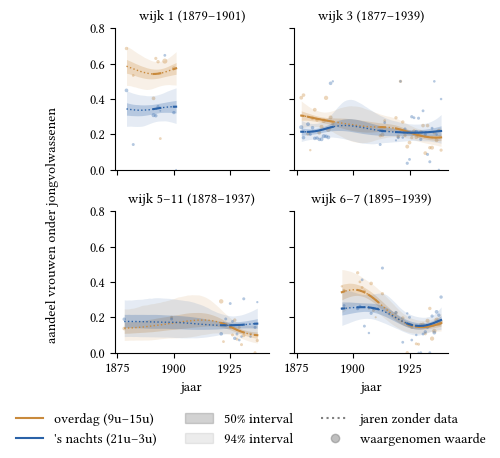

In [44]:
def lijn_met_gaten(ax, sel, kleur):
    """Doorgetrokken waar data zijn, gestippeld over ontbrekende jaren."""
    ax.plot(sel["year"], sel["mediaan"], ":", color=kleur, lw=1)
    ax.plot(sel["year"], sel["mediaan"].where(sel["data"]), "-", color=kleur)


fig, axes = plt.subplots(2, 2, figsize=(TEKSTBREEDTE, 4.6), sharex=True, sharey=True)

for ax, w in zip(axes.flat, WIJKEN):
    for d in ["dag", "nacht"]:
        sel = aandeel[(aandeel["wijk"] == w) & (aandeel["dagdeel"] == d)]
        ax.fill_between(sel["year"], sel["lo94"], sel["hi94"], color=KLEUREN_DD[d], alpha=0.12, lw=0)
        ax.fill_between(sel["year"], sel["lo50"], sel["hi50"], color=KLEUREN_DD[d], alpha=0.25, lw=0)
        lijn_met_gaten(ax, sel, KLEUREN_DD[d])

        obs = dagdeel_data[(dagdeel_data["wijk"] == w) & (dagdeel_data["dagdeel"] == d)]
        ax.scatter(obs["year"], obs["n_vrouw"] / obs["n_tot"], s=np.sqrt(obs["n_tot"]),
                   color=KLEUREN_DD[d], alpha=0.35, lw=0)

    ax.set_title(f"{TITELS[w]} ({bereik.loc[w, 'min']}–{bereik.loc[w, 'max']})", fontsize=CORPS)
    ax.set_ylim(0, 0.8)
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes[1]:
    ax.set_xlabel("jaar")
fig.supylabel("aandeel vrouwen onder jongvolwassenen", fontsize=CORPS)

handles = [
    plt.Line2D([], [], color=KLEUREN_DD["dag"], label="overdag (9u–15u)"),
    plt.Line2D([], [], color=KLEUREN_DD["nacht"], label="'s nachts (21u–3u)"),
    plt.Rectangle((0, 0), 1, 1, color="grey", alpha=0.35, label="50% interval"),
    plt.Rectangle((0, 0), 1, 1, color="grey", alpha=0.15, label="94% interval"),
    plt.Line2D([], [], ls=":", color="grey", label="jaren zonder data"),
    plt.Line2D([], [], ls="", marker="o", color="grey", alpha=0.5, label="waargenomen waarde"),
]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=CORPS)
fig.tight_layout(rect=[0.02, 0.1, 1, 1])

#fig.savefig(FIG_DIR / "afbeelding2_aandeel_vrouwen_dag_nacht.png", dpi=300)

In [45]:
DAGDEEL_DEFINITIES = {
    "astro": ("astro", {
        "dag": ["dag"],
        "nacht": ["avondschemering", "nacht", "ochtendschemering"],
    }),
    "klok": ("E_TIME_grouped", {
        "dag": ["9u-12u", "12u-15u"],
        "nacht": ["21u-0u", "0u-3u"],
    }),
}

In [46]:
def dag_nacht_tabel(data, groep):
    """Aandeel vrouwen overdag en 's nachts per groep, met chi-kwadraattoets."""
    rijen = []
    for naam, sub in data.groupby(groep, observed=True):
        t = (pd.crosstab(sub["gender_inferred"], sub["dagdeel"])
             .reindex(index=["woman", "man"], columns=["dag", "nacht"], fill_value=0))
        chi2, p, _, _ = chi2_contingency(t, correction=False)
        vrouwen = t.loc["woman"] / t.sum()
        rijen.append({
            groep: naam,
            "dag (n)": t["dag"].sum(),
            "nacht (n)": t["nacht"].sum(),
            "vrouwen dag (%)": round(100 * vrouwen["dag"], 1),
            "vrouwen nacht (%)": round(100 * vrouwen["nacht"], 1),
            "verschil (pp)": round(100 * (vrouwen["nacht"] - vrouwen["dag"]), 1),
            "p": round(p, 3),
            "V": round(np.sqrt(chi2 / t.values.sum()), 3),
        })
    return pd.DataFrame(rijen)

In [47]:
AFBAKENING = "klok"  # "astro" (zonsondergang) of "klok" (9u–15u en 21u–3u)

YEAR_MIN, YEAR_MAX = 1877, 1939

DAGDEEL_DEFINITIES = {
    "astro": ("astro", {
        "dag": ["dag"],
        "nacht": ["avondschemering", "nacht", "ochtendschemering"],
    }),
    "klok": ("E_TIME_grouped", {
        "dag": ["9u-12u", "12u-15u"],
        "nacht": ["21u-0u", "0u-3u"],
    }),
}

LEEFTIJD_GRENZEN = [0, 5, 15, 25, 65, np.inf]
LEEFTIJD_LABELS = ["Jong kind (0–4)", "Kind (5–14)", "Jongvolwassene (15–24)",
                   "Volwassene (25–64)", "Oudere (65+)"]

WIJK_SAMENVOEGEN = {7: 6, 11: 5}
WIJKEN = ["1", "3", "5", "6"]
TITELS = {"1": "wijk 1", "3": "wijk 3", "5": "wijk 5–11", "6": "wijk 6–7"}

DATA_DIR = Path("../../data/algemeen/gebeurtenisdata_macro")
OUT_DIR = Path("../../tab/H7")

In [48]:
kolom, categorieen = DAGDEEL_DEFINITIES[AFBAKENING]
omzetting = {waarde: deel for deel, waarden in categorieen.items() for waarde in waarden}

basis = df.assign(dagdeel=df[kolom].map(omzetting))
basis = basis[
    basis["gender_inferred"].isin(["man", "woman"])
    & basis["year"].between(YEAR_MIN, YEAR_MAX)
    & basis["P_AGE_clean"].notna()
    & basis["dagdeel"].notna()
].copy()

basis["leeftijdsgroep"] = pd.cut(basis["P_AGE_clean"], LEEFTIJD_GRENZEN,
                                 labels=LEEFTIJD_LABELS, right=False)
basis["wijk"] = basis["district"].replace(WIJK_SAMENVOEGEN)

print(f"Afbakening: {AFBAKENING} | personen: {len(basis):,}")
print(basis["dagdeel"].value_counts())

Afbakening: klok | personen: 29,430
dagdeel
dag      18645
nacht    10785
Name: count, dtype: int64


In [49]:
tabel1 = pd.concat([
    dag_nacht_tabel(basis, "leeftijdsgroep").iloc[::-1],
    dag_nacht_tabel(basis.assign(leeftijdsgroep="Totaal"), "leeftijdsgroep"),
], ignore_index=True)

print(tabel1.to_string(index=False))
#tabel1.to_csv(OUT_DIR / f"H3_tabel1_dag_nacht_leeftijd_{AFBAKENING}.csv", index=False)

        leeftijdsgroep  dag (n)  nacht (n)  vrouwen dag (%)  vrouwen nacht (%)  verschil (pp)     p     V
          Oudere (65+)      591        262             28.3               25.2           -3.1 0.354 0.032
    Volwassene (25–64)    13002       7805             20.9               19.4           -1.5 0.009 0.018
Jongvolwassene (15–24)     4093       2407             25.7               22.1           -3.6 0.001 0.040
           Kind (5–14)      877        273             25.3               26.7            1.4 0.637 0.014
       Jong kind (0–4)       82         38             39.0               23.7          -15.3 0.099 0.150
                Totaal    18645      10785             22.5               20.4           -2.1 0.000 0.025


In [50]:
jongvolwassenen = (
    basis[basis["leeftijdsgroep"] == "Jongvolwassene (15–24)"]
    .dropna(subset=["wijk"])
    .assign(wijk=lambda d: d["wijk"].astype(int).astype(str))
)

tabel2 = pd.concat([
    dag_nacht_tabel(jongvolwassenen[jongvolwassenen["wijk"].isin(WIJKEN)], "wijk"),
    dag_nacht_tabel(jongvolwassenen.assign(wijk="Totaal"), "wijk"),
], ignore_index=True)
tabel2["wijk"] = tabel2["wijk"].map(TITELS).fillna(tabel2["wijk"])

print(tabel2.to_string(index=False))
#tabel2.to_csv(OUT_DIR / f"H3_tabel2_dag_nacht_wijk_{AFBAKENING}.csv", index=False)

     wijk  dag (n)  nacht (n)  vrouwen dag (%)  vrouwen nacht (%)  verschil (pp)     p     V
   wijk 1      416        259             57.0               34.7          -22.2 0.000 0.216
   wijk 3     1958       1149             23.9               21.8           -2.1 0.189 0.024
wijk 5–11      452        322             15.3               15.8            0.6 0.828 0.008
 wijk 6–7     1102        607             19.1               19.9            0.8 0.694 0.010
   Totaal     4093       2407             25.7               22.1           -3.6 0.001 0.040
